In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_csv("StudentsPerformance.csv")

In [ ]:
df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [ ]:
df.shape

(1000, 8)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   gender                       1000 non-null   object
 1   race/ethnicity               1000 non-null   object
 2   parental level of education  1000 non-null   object
 3   lunch                        1000 non-null   object
 4   test preparation course      1000 non-null   object
 5   math score                   1000 non-null   int64 
 6   reading score                1000 non-null   int64 
 7   writing score                1000 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 62.6+ KB


In [ ]:
df.describe()

,math score,reading score,writing score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


In [ ]:
df.isnull().sum()

,0
gender,0
race/ethnicity,0
parental level of education,0
lunch,0
test preparation course,0
math score,0
reading score,0
writing score,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.columns

Index(['gender', 'race/ethnicity', 'parental level of education', 'lunch',
       'test preparation course', 'math score', 'reading score',
       'writing score'],
      dtype='object')

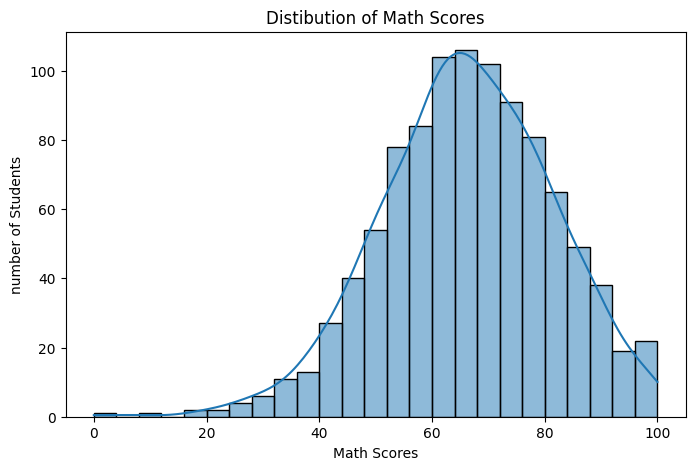

In [ ]:
plt.figure(figsize=(8,5))
sns.histplot(df['math score'], kde = True)
plt.title("Distibution of Math Scores")
plt.xlabel("Math Scores")
plt.ylabel("number of Students")
plt.show()

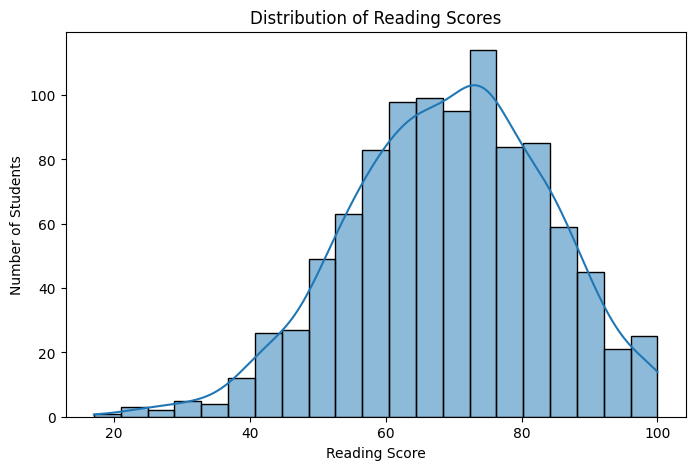

In [ ]:
plt.figure(figsize=(8,5))
sns.histplot(df["reading score"], kde=True)
plt.title("Distribution of Reading Scores")
plt.xlabel("Reading Score")
plt.ylabel("Number of Students")
plt.show()

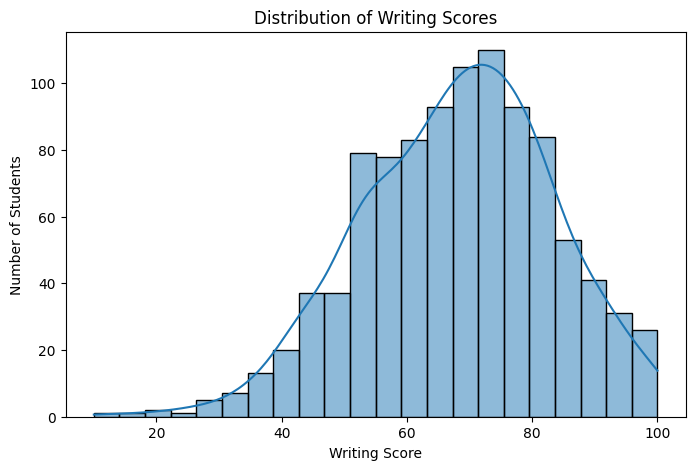

In [ ]:
plt.figure(figsize=(8,5))
sns.histplot(df["writing score"], kde=True)
plt.title("Distribution of Writing Scores")
plt.xlabel("Writing Score")
plt.ylabel("Number of Students")
plt.show()

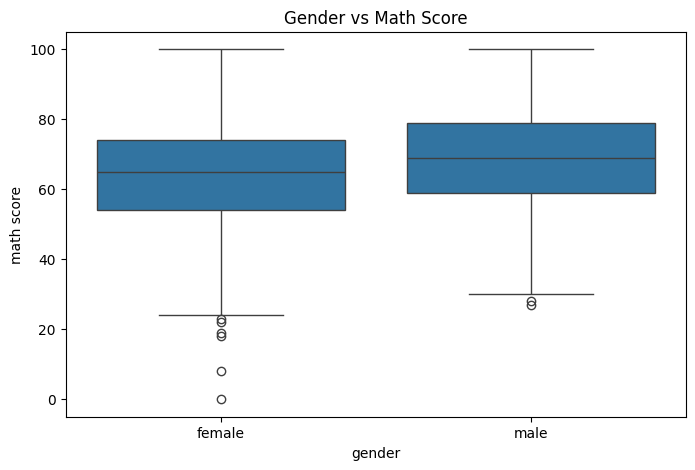

In [ ]:
plt.figure(figsize=(8,5))
sns.boxplot(x="gender", y="math score", data=df)
plt.title("Gender vs Math Score")
plt.show()

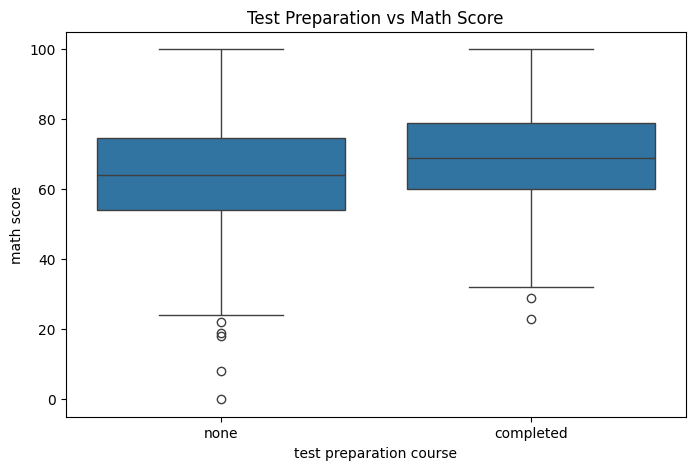

In [ ]:
plt.figure(figsize=(8,5))
sns.boxplot(x = "test preparation course", y = "math score", data = df)
plt.title("Test Preparation vs Math Score")
plt.show()

In [ ]:
x = df.drop("math score", axis = 1)
y = df["math score"]

In [ ]:
x.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,74
1,female,group C,some college,standard,completed,90,88
2,female,group B,master's degree,standard,none,95,93
3,male,group A,associate's degree,free/reduced,none,57,44
4,male,group C,some college,standard,none,78,75


In [ ]:
y.head()

,math score
0,72
1,69
2,90
3,47
4,76


In [ ]:
x.dtypes

,0
gender,object
race/ethnicity,object
parental level of education,object
lunch,object
test preparation course,object
reading score,int64
writing score,int64


In [ ]:
X = pd.get_dummies(x, drop_first = True)

In [ ]:
X.head()

,reading score,writing score,gender_male,race/ethnicity_group B,race/ethnicity_group C,race/ethnicity_group D,race/ethnicity_group E,parental level of education_bachelor's degree,parental level of education_high school,parental level of education_master's degree,parental level of education_some college,parental level of education_some high school,lunch_standard,test preparation course_none
0,72,74,False,True,False,False,False,True,False,False,False,False,True,True
1,90,88,False,False,True,False,False,False,False,False,True,False,True,False
2,95,93,False,True,False,False,False,False,False,True,False,False,True,True
3,57,44,True,False,False,False,False,False,False,False,False,False,False,True
4,78,75,True,False,True,False,False,False,False,False,True,False,True,True


In [ ]:
y.head()

,math score
0,72
1,69
2,90
3,47
4,76


In [ ]:
X.dtypes

,0
reading score,int64
writing score,int64
gender_male,bool
race/ethnicity_group B,bool
race/ethnicity_group C,bool
race/ethnicity_group D,bool
race/ethnicity_group E,bool
parental level of education_bachelor's degree,bool
parental level of education_high school,bool
parental level of education_master's degree,bool


In [ ]:
X.shape

(1000, 14)

In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size =0.2, random_state = 42)

In [ ]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (800, 14)
X_test: (200, 14)
y_train: (800,)
y_test: (200,)


In [ ]:
from sklearn.preprocessing import StandardScaler

In [ ]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
from sklearn.linear_model import LinearRegression

In [ ]:
model = LinearRegression()
model.fit(X_train_scaled, y_train)

LinearRegression()

In [ ]:
y_pred = model.predict(X_test_scaled)

In [ ]:
y_pred[:10]

array([76.3879697 , 58.88597004, 76.99026483, 76.85180448, 87.62737816,
       79.0140238 , 64.65460865, 53.00791885, 74.18471015, 49.21353815])

In [ ]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [ ]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

In [ ]:
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2 )

MAE: 4.214763142474851
MSE: 29.095169866715494
RMSE: 5.393993869732843
R2 Score: 0.8804332983749564


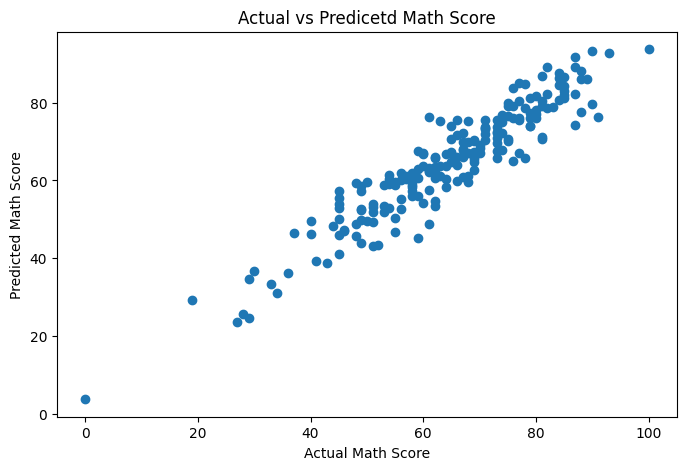

In [ ]:
plt.figure(figsize=(8,5))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Math Score")
plt.ylabel("Predicted Math Score")
plt.title("Actual vs Predicetd Math Score")
plt.show()

In [ ]:
from sklearn.tree import DecisionTreeRegressor

In [ ]:
dt_model = DecisionTreeRegressor(random_state = 42, max_depth = 5)

dt_model.fit(X_train, y_train)

DecisionTreeRegressor(max_depth=5, random_state=42)

In [ ]:
dt_pred = dt_model.predict(X_test)

In [ ]:
dt_mae= mean_absolute_error(y_test, dt_pred)
dt_mse = mean_squared_error(y_test, dt_pred)
dt_rmse = np.sqrt(dt_mse)
dt_r2 = r2_score(y_test, dt_pred)

print("Decision Tree Model Performance:")
print(" Decision Tree MAE:", dt_mae)
print(" Decision Tree MSE:", dt_mse)
print(" Decision Tree RMSE:", dt_rmse)
print(" Decision Tree R2 Score:", dt_r2)

Decision Tree Model Performance:
 Decision Tree MAE: 4.931523210662771
 Decision Tree MSE: 42.77161032657878
 Decision Tree RMSE: 6.540000789493743
 Decision Tree R2 Score: 0.8242299188020519


In [ ]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(n_estimators = 100, random_state = 42)

rf_model.fit(X_train, y_train)

RandomForestRegressor(random_state=42)

In [ ]:
rf_pred = rf_model.predict(X_train)

rf_pred = rf_model.predict(X_test)
print("Actual:", len(y_test))
print("Predicted:", len(rf_pred))

Actual: 200
Predicted: 200


In [ ]:
rf_mae = mean_absolute_error(y_test, rf_pred)
rf_mse = mean_squared_error(y_test, rf_pred)
rf_rmse = np.sqrt(rf_mse)
rf_r2 = r2_score(y_test, rf_pred)

print("Random Forest MAE:", rf_model)
print("Random Forest MSE:", rf_mse)
print("Random Forest RMSE:", rf_model)
print("Random Forest R2:", rf_r2)

Random Forest MAE: RandomForestRegressor(random_state=42)
Random Forest MSE: 36.69565650921202
Random Forest RMSE: RandomForestRegressor(random_state=42)
Random Forest R2: 0.8491990721184489


In [ ]:
results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decison Tree",
        "Random Forest"
    ],
    "MAE": [
        mae,
        dt_mae,
        rf_mae
    ],
    "MSE": [
        mse,
        dt_mse,
        rf_mse
    ],
    "RMSE": [
        rmse,
        dt_rmse,
        rf_rmse
    ],
    "R2 Score": [
        r2,
        dt_r2,
        rf_r2
    ]
})

results

,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,4.214763,29.095170,5.393994,0.880433
1,Decison Tree,4.931523,42.771610,6.540001,0.824230
2,Random Forest,4.740643,36.695657,6.057694,0.849199


In [ ]:
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_

})

feature_importance = feature_importance.sort_values(by = "Importance", ascending = False)

feature_importance.head(10)

,Feature,Importance
0,reading score,0.562565
1,writing score,0.234740
2,gender_male,0.120780
12,lunch_standard,0.015490
13,test preparation course_none,0.011255
6,race/ethnicity_group E,0.011117
10,parental level of education_some college,0.008142
4,race/ethnicity_group C,0.006833
5,race/ethnicity_group D,0.006085
8,parental level of education_high school,0.006068


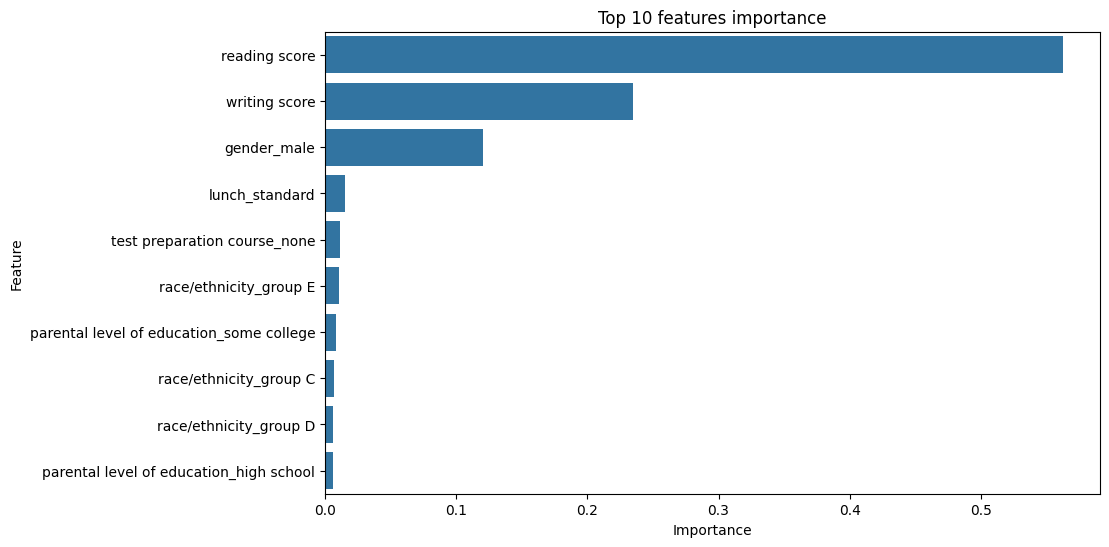

In [ ]:
plt.figure(figsize=(10,6))

sns.barplot(data = feature_importance.head(10), x = "Importance", y = "Feature")
plt.title("Top 10 features importance")
plt.show()


In [ ]:
sample = X_test.iloc[[0]]

prediction = rf_model.predict(sample)

print("Predicted Math Score:", prediction[0])

Predicted Math Score: 75.54


In [ ]:
comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MAE": [mae, rf_mae],
    "MSE": [mse, rf_mse],
    "RMSE": [rmse, rf_rmse],
    "R2 Score": [r2, rf_r2]
})

comparison

,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,4.214763,29.095170,5.393994,0.880433
1,Random Forest,4.740643,36.695657,6.057694,0.849199


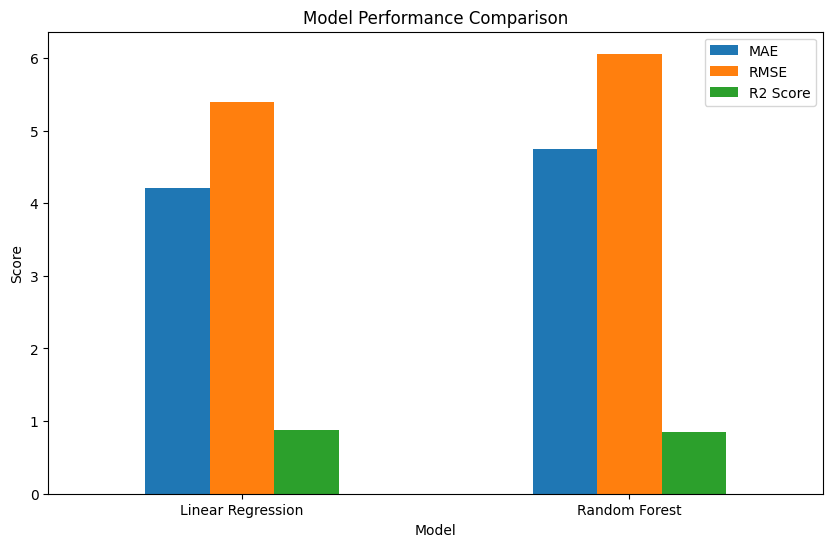

In [ ]:
comparison.set_index("Model")[["MAE","RMSE","R2 Score"]].plot(kind = "bar", figsize = (10,6))
plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.xticks(rotation = 0)
plt.show()

In [ ]:
import joblib

joblib.dump(rf_model, "student_performance_model.pkl")

print("Model Saved Successfully")

Model Saved Successfully


In [ ]:
loaded_model = joblib.load("student_performance_model.pkl")

print("Model Loaded Successfully!")

Model Loaded Successfully!


In [ ]:
sample=X_test.iloc[[0]]

prediction = loaded_model.predict(sample)

print("Predicted Math Score:", prediction[0])

Predicted Math Score: 75.54


## Conclusion

In this project, we predicted student's math scores using Machine Learning

Steps Performed:
-Data preprocessing
-Feature encoding
-Train-test-split
-Linear Regresson
-Random Forest Regresson
-Model evaluation using MAE, MSE, RMSE, R2
-Model comparison
-Model saving and loading
-Sample prediction

The trained Random Forest moddel was used to predict the math score of a sample student